# 🧠 Sesión 09-A — Ejemplo 1: Feature Extraction + Fine-Tuning
## Malaria Cell Images + MobileNetV2

**Curso:** IS056B — Ingeniería del Conocimiento  
**Docente:** Msc. Jaime Antonio Huaytalla Pariona  
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas  
**Semestre:** 2026-II | **Unidad II**

---

### 🎯 Objetivo
Clasificación binaria (**parasitized** vs **uninfected**) usando Transfer Learning en dos fases:
1. **Feature Extraction**: MobileNetV2 congelado + clasificador nuevo
2. **Fine-Tuning**: descongelar ~30% superior del backbone con LR bajo

### 📦 Dataset
- **Malaria Cell Images** (TFDS): ~27,558 imágenes de frotis sanguíneos
- Split: 70% train / 15% val / 15% test

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [5]:
import subprocess
gpu_info = subprocess.run(
    ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
    capture_output=True, text=True)
print("🖥️ GPU:", gpu_info.stdout.strip() or "⚠️ Activa GPU: Runtime > Change runtime type > T4")

🖥️ GPU: Tesla T4, 15360 MiB


In [6]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
warnings.filterwarnings('ignore')

# Reproducibilidad
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Visualización
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Hiperparámetros globales
IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
AUTOTUNE    = tf.data.AUTOTUNE

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 🟢 Ejemplo 1 — Detección de Malaria con MobileNetV2

**Objetivo:** Clasificación binaria (célula infectada vs. sana) con Transfer Learning + Fine-Tuning.

**Dataset:** [Malaria Cell Images](https://www.tensorflow.org/datasets/catalog/malaria) (~27,558 imágenes, ~337 MB)

**Estrategia:**
1. Fase 1 → Feature Extraction (backbone congelado).
2. Fase 2 → Fine-Tuning de las capas superiores (LR bajo).

### Montar Drive

In [7]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR    = '/content/drive/MyDrive/IS056B_Semana09'
MODEL_DIR   = os.path.join(BASE_DIR, 'modelos')
RESULTS_DIR = os.path.join(BASE_DIR, 'resultados')

# Subcarpeta específica del Ejemplo 1
EJ1_MODELS  = os.path.join(MODEL_DIR,   'Ej1_Malaria')
EJ1_RESULTS = os.path.join(RESULTS_DIR, 'Ej1_Malaria')
for d in (EJ1_MODELS, EJ1_RESULTS):
    os.makedirs(d, exist_ok=True)

print("📁 Modelos:    ", EJ1_MODELS)
print("📁 Resultados: ", EJ1_RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Modelos:     /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria
📁 Resultados:  /content/drive/MyDrive/IS056B_Semana09/resultados/Ej1_Malaria


In [8]:
# Instalar importlib-resources (dependencia de TFDS)
!pip install -q importlib-resources

print("✅ importlib-resources instalado")

✅ importlib-resources instalado


## 🦠 Dataset: Malaria Cell Images

- ~27,558 imágenes de frotis sanguíneos
- 2 clases: `parasitized` / `uninfected`
- Split manual: 70% train / 15% val / 15% test (TFDS solo trae `train`)
- Se calcula `class_weight` para compensar desbalance

In [9]:
# Malaria tiene solo el split "train" -> lo dividimos manualmente
(train_raw, val_raw, test_raw), info = tfds.load(
    'malaria',
    split=['train[:70%]', 'train[70%:85%]', 'train[85%:]'],
    as_supervised=True,
    with_info=True
)

NUM_CLASSES = info.features['label'].num_classes
CLASS_NAMES = info.features['label'].names

n_train = tf.data.experimental.cardinality(train_raw).numpy()
n_val   = tf.data.experimental.cardinality(val_raw).numpy()
n_test  = tf.data.experimental.cardinality(test_raw).numpy()

print(f"📊 Clases ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"📊 Train: {n_train:,} | Val: {n_val:,} | Test: {n_test:,}")
print(f"📊 Total: {n_train + n_val + n_test:,}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.HBRPOI_1.0.0/malaria-train.tfrecord-[0-9][0-9][0-9][0-9…

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.
📊 Clases (2): ['parasitized', 'uninfected']
📊 Train: 19,291 | Val: 4,133 | Test: 4,134
📊 Total: 27,558


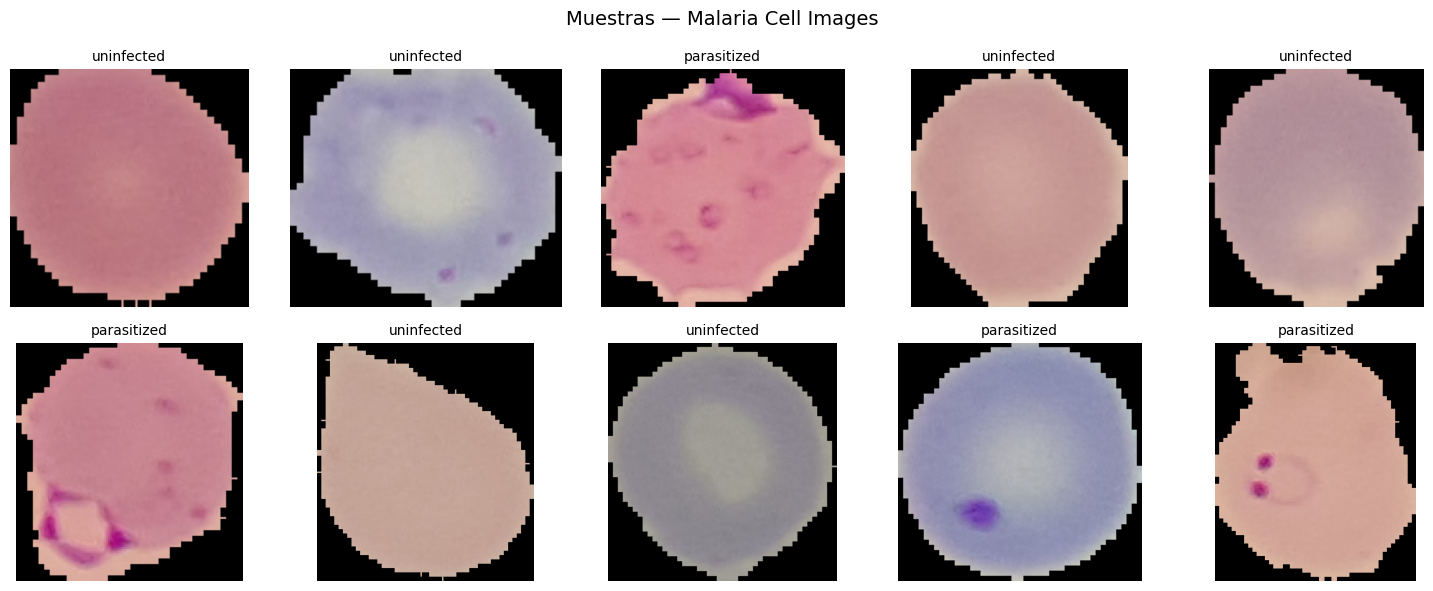

In [10]:
# Visualizar muestras
plt.figure(figsize=(15, 6))
for i, (img, label) in enumerate(train_raw.take(10)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(img.numpy())
    plt.title(CLASS_NAMES[label.numpy()], fontsize=10)
    plt.axis('off')
plt.suptitle('Muestras — Malaria Cell Images', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(EJ1_RESULTS, 'muestras_malaria.png'),
            dpi=100, bbox_inches='tight')
plt.show()

### Balance de clases + class_weight

Distribución TRAIN: {'parasitized': 9641, 'uninfected': 9650}
Distribución VAL:   {'parasitized': 2052, 'uninfected': 2081}
class_weight: {0: 1.0004667565605228, 1: 0.9995336787564767}


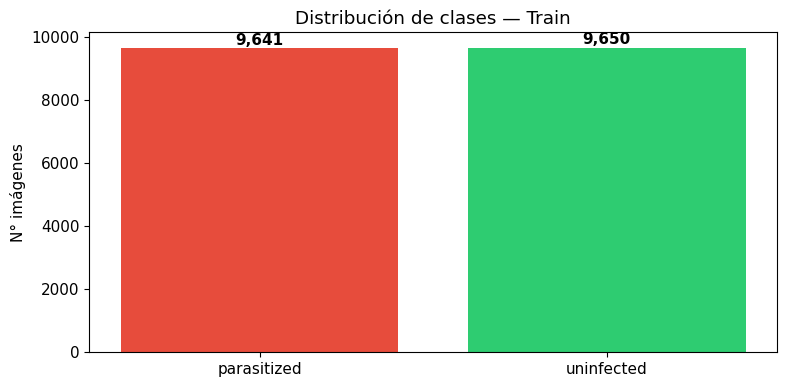

In [11]:
IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32

# Función de preprocesamiento
def preprocess_example1(image, label):
    image = tf.image.resize(image, IMG_SIZE_1)
    # MobileNetV2 espera píxeles en [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES_1)
    return image, label

# Crear pipelines
train_ds_1 = (train_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

val_ds_1 = (val_raw
    .map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

## 🔄 Pipeline tf.data + Data Augmentation

- Resize → 224×224
- Augmentation **solo en train**: flip, rotación, zoom, contraste, traslación
- Preprocesamiento propio de MobileNetV2 (escala `[-1, 1]`)
- `shuffle`, `batch`, `prefetch(AUTOTUNE)`

In [12]:
# Augmentation (solo en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10),
    layers.RandomTranslation(0.10, 0.10),
], name='augmentation')

def preprocess(img, label, train=False):
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)
    if train:
        img = data_augmentation(img, training=True)
    # Preprocesamiento MobileNetV2 -> escala [-1, 1]
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)
    return img, label

train_ds = (train_raw
    .map(lambda x, y: preprocess(x, y, train=True),  num_parallel_calls=AUTOTUNE)
    .shuffle(2000, seed=SEED)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

val_ds = (val_raw
    .map(lambda x, y: preprocess(x, y, train=False), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

test_ds = (test_raw
    .map(lambda x, y: preprocess(x, y, train=False), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

print("✅ Pipelines listos")
print(f"   Batches train: {tf.data.experimental.cardinality(train_ds).numpy()}")
print(f"   Batches val:   {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"   Batches test:  {tf.data.experimental.cardinality(test_ds).numpy()}")

✅ Pipelines listos
   Batches train: 603
   Batches val:   130
   Batches test:  130


## 🧱 Modelo — Feature Extraction

- Backbone **MobileNetV2** pre-entrenado en ImageNet (congelado)
- `GlobalAveragePooling2D` → `Dropout` → `Dense(128)` → `Dropout` → `Dense(1, sigmoid)`
- Optimizador: **Adam(1e-3)** — pérdida: `binary_crossentropy`
- Métricas: accuracy, AUC, precision, recall

In [13]:
base_model = MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False   # Fase 1: Feature Extraction

print(f"✅ MobileNetV2 cargado")
print(f"   Capas:       {len(base_model.layers)}")
print(f"   Parámetros:  {base_model.count_params():,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ MobileNetV2 cargado
   Capas:       154
   Parámetros:  2,257,984


Construir y compilar modelo

In [14]:
inputs  = layers.Input(shape=(*IMG_SIZE, 3), name='input')
x       = base_model(inputs, training=False)
x       = layers.GlobalAveragePooling2D(name='gap')(x)
x       = layers.Dropout(0.30, name='drop1')(x)
x       = layers.Dense(128, activation='relu', name='fc1')(x)
x       = layers.Dropout(0.20, name='drop2')(x)
outputs = layers.Dense(1, activation='sigmoid', name='pred')(x)

model = models.Model(inputs, outputs, name='Malaria_MobileNetV2')

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='prec'),
             tf.keras.metrics.Recall(name='rec')]
)

model.summary()

Model: "Malaria_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
def get_callbacks(fase_name):
    ckpt_path = os.path.join(EJ1_MODELS, f'best_{fase_name}.keras')
    return [
        callbacks.ModelCheckpoint(ckpt_path, monitor='val_accuracy',
                                  save_best_only=True, mode='max', verbose=1),
        callbacks.EarlyStopping(monitor='val_accuracy', patience=5,
                                restore_best_weights=True, mode='max', verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                                    patience=3, min_lr=1e-7, verbose=1),
    ]

print("✅ Callbacks listos")

✅ Callbacks listos


> 💡 **Observa:** Solo ~2,560 parámetros son entrenables (el clasificador). Los ~2.2M del backbone están congelados. ¡Esto es Feature Extraction!

## 🚀 Fase 1: Entrenamiento (backbone congelado)

- **15 épocas máx.** con EarlyStopping (patience=5)
- `class_weight` aplicado para el desbalance
- Se guarda el mejor modelo en `modelos/Ej1_Malaria/best_fase1.keras`

In [16]:
EPOCHS_F1 = 15

history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_F1,
    class_weight=class_weight,
    callbacks=get_callbacks('fase1'),
    verbose=1
)

Epoch 1/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 633ms/step - accuracy: 0.8316 - auc: 0.9049 - loss: 0.3839 - prec: 0.8202 - rec: 0.8514
Epoch 1: val_accuracy improved from None to 0.91895, saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/best_fase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/best_fase1.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 465s 669ms/step - accuracy: 0.8706 - auc: 0.9408 - loss: 0.3101 - prec: 0.8588 - rec: 0.8872 - val_accuracy: 0.9189 - val_auc: 0.9785 - val_loss: 0.2074 - val_prec: 0.8836 - val_rec: 0.9664 - learning_rate: 0.0010
Epoch 2/15
602/603 ━━━━━━━━━━━━━━━━━━━━ 0s 583ms/step - accuracy: 0.8952 - auc: 0.9573 - loss: 0.2614 - prec: 0.8865 - rec: 0.9087
Epoch 2: val_accuracy did not improve from 0.91895
603/603 ━━━━━━━━━━━━━━━━━━━━ 401s 594ms/step - accuracy: 0.8958 - auc: 0.9579 - loss: 0.2609 - prec: 0.8870 - rec: 0.9074 - val_accuracy: 0.9061 - val_auc: 0.9792 - val_loss: 0.2211 - val_

## Curvas Fase 1

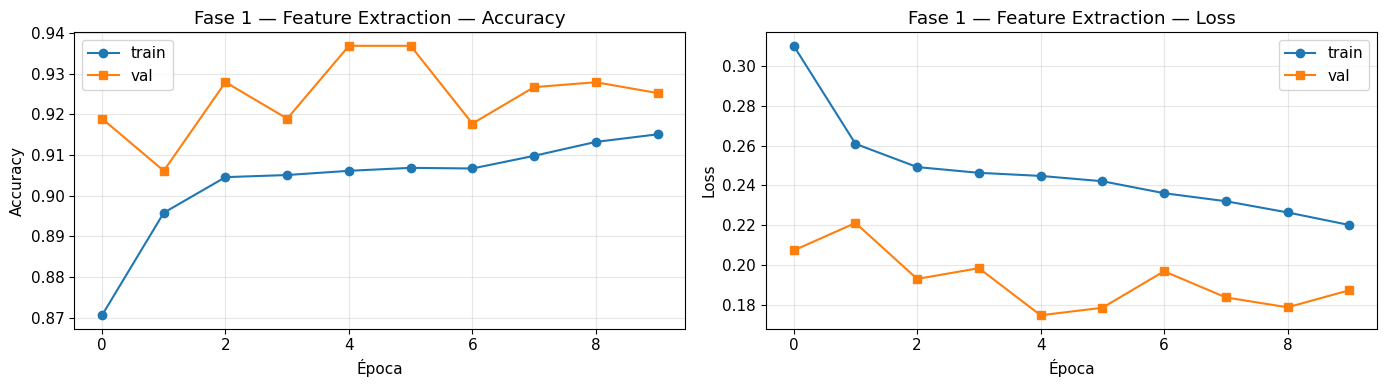

In [17]:
def plot_history(history, titulo, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history['accuracy'],     label='train', marker='o')
    axes[0].plot(history.history['val_accuracy'], label='val',   marker='s')
    axes[0].set_title(f'{titulo} — Accuracy')
    axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='train', marker='o')
    axes[1].plot(history.history['val_loss'], label='val',   marker='s')
    axes[1].set_title(f'{titulo} — Loss')
    axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(EJ1_RESULTS, fname), dpi=100, bbox_inches='tight')
    plt.show()

plot_history(history_1, 'Fase 1 — Feature Extraction', 'curvas_fase1.png')

## 🔓 Fase 2: Fine-Tuning

- Descongelar **~30% superior** del backbone (últimas capas de MobileNetV2)
- **BatchNorm siempre en modo inferencia** (`trainable=False`)
- Recompilar con **Adam(1e-5)** (LR 100× menor)
- 15 épocas máx. con los mismos callbacks → guarda en `best_fase2.keras`

In [18]:
base_model.trainable = True

# Descongelar solo las últimas ~30% capas del backbone
total_layers    = len(base_model.layers)
fine_tune_from  = int(total_layers * 0.70)
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# IMPORTANTE: BatchNorm siempre en modo inferencia durante fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f"🔓 Capas descongeladas: {trainable}/{total_layers}")
print(f"   (a partir de la capa {fine_tune_from})")

# Recompilar con LR bajo
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='prec'),
             tf.keras.metrics.Recall(name='rec')]
)

🔓 Capas descongeladas: 31/154
   (a partir de la capa 107)


In [19]:
EPOCHS_F2 = 15

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_F2,
    class_weight=class_weight,
    callbacks=get_callbacks('fase2'),
    verbose=1
)

Epoch 1/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.9221 - auc: 0.9710 - loss: 0.2126 - prec: 0.9108 - rec: 0.9372
Epoch 1: val_accuracy improved from None to 0.95088, saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/best_fase2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/best_fase2.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 402s 571ms/step - accuracy: 0.9303 - auc: 0.9758 - loss: 0.1934 - prec: 0.9176 - rec: 0.9457 - val_accuracy: 0.9509 - val_auc: 0.9887 - val_loss: 0.1317 - val_prec: 0.9384 - val_rec: 0.9659 - learning_rate: 1.0000e-05
Epoch 2/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 529ms/step - accuracy: 0.9435 - auc: 0.9818 - loss: 0.1615 - prec: 0.9303 - rec: 0.9597
Epoch 2: val_accuracy improved from 0.95088 to 0.95693, saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/best_fase2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_M

Curvas Fase 2

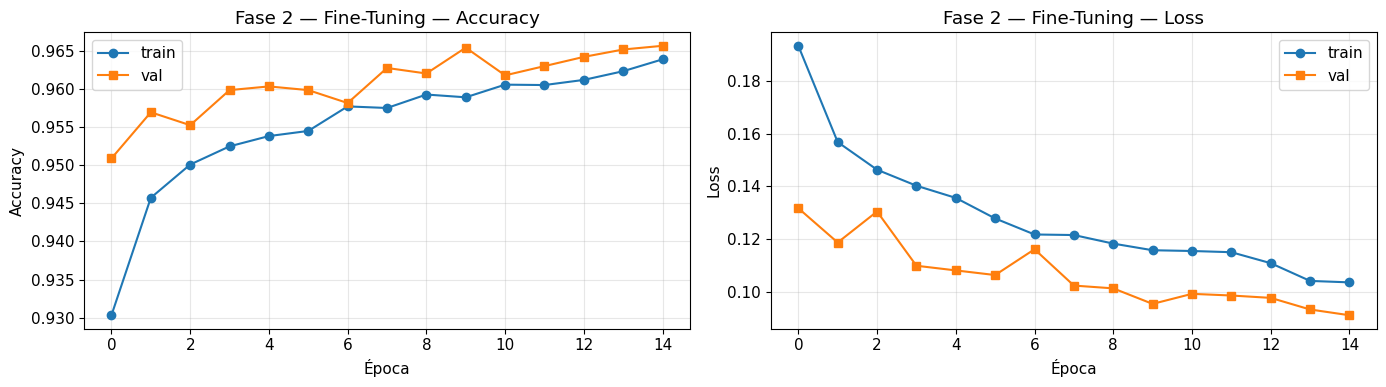

In [20]:
plot_history(history_2, 'Fase 2 — Fine-Tuning', 'curvas_fase2.png')

## 🧪 Evaluación en TEST + Guardado de artefactos

- Métricas finales en test
- `classification_report` + **matriz de confusión**
- Se guarda `modelo_final_malaria.keras` y `metricas_ejemplo1.csv`

📊 Métricas en TEST:
   loss      : 0.1081
   compile_metrics: 0.9659

=== Classification Report ===
              precision    recall  f1-score   support

 parasitized     0.9841    0.9477    0.9656      2086
  uninfected     0.9487    0.9844    0.9662      2048

    accuracy                         0.9659      4134
   macro avg     0.9664    0.9661    0.9659      4134
weighted avg     0.9666    0.9659    0.9659      4134



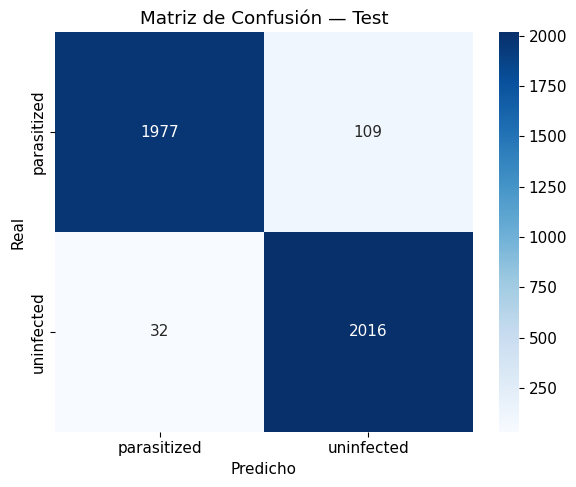


💾 Modelo final: /content/drive/MyDrive/IS056B_Semana09/modelos/Ej1_Malaria/modelo_final_malaria.keras
💾 Métricas: /content/drive/MyDrive/IS056B_Semana09/resultados/Ej1_Malaria/metricas_ejemplo1.csv



,fase,epochs,best_val_acc,best_val_loss,test_loss,test_accuracy,test_auc
0,Fase 1 — Feature Extraction,10,0.936850,0.174815,0.108138,0.965893,0.992157
1,Fase 2 — Fine-Tuning,15,0.965642,0.091087,0.108138,0.965893,0.992157


In [21]:
# ---- 1) Métricas en TEST ----
test_metrics = model.evaluate(test_ds, verbose=0)
print("📊 Métricas en TEST:")
for name, val in zip(model.metrics_names, test_metrics):
    print(f"   {name:10s}: {val:.4f}")

# ---- 2) Predicciones ----
y_true, y_pred_prob = [], []
for x, y in test_ds:
    p = model.predict(x, verbose=0).ravel()
    y_true.extend(y.numpy())
    y_pred_prob.extend(p)

y_true      = np.array(y_true).astype(int)
y_pred_prob = np.array(y_pred_prob)
y_pred      = (y_pred_prob >= 0.5).astype(int)

# ---- 3) Classification Report ----
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred,
                            target_names=CLASS_NAMES, digits=4))

# ---- 4) Matriz de confusión ----
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Matriz de Confusión — Test')
plt.xlabel('Predicho'); plt.ylabel('Real')
plt.tight_layout()
plt.savefig(os.path.join(EJ1_RESULTS, 'confusion_matrix_test.png'),
            dpi=100, bbox_inches='tight')
plt.show()

# ---- 5) Guardar modelo final ----
final_path = os.path.join(EJ1_MODELS, 'modelo_final_malaria.keras')
model.save(final_path)
print(f"\n💾 Modelo final: {final_path}")

# ---- 6) Guardar métricas comparativas ----
metrics_df = pd.DataFrame([
    {'fase': 'Fase 1 — Feature Extraction',
     'epochs': len(history_1.history['loss']),
     'best_val_acc': max(history_1.history['val_accuracy']),
     'best_val_loss': min(history_1.history['val_loss'])},
    {'fase': 'Fase 2 — Fine-Tuning',
     'epochs': len(history_2.history['loss']),
     'best_val_acc': max(history_2.history['val_accuracy']),
     'best_val_loss': min(history_2.history['val_loss'])},
])
metrics_df['test_loss']     = test_metrics[0]
metrics_df['test_accuracy'] = test_metrics[1]
metrics_df['test_auc']      = test_metrics[2]

csv_path = os.path.join(EJ1_RESULTS, 'metricas_ejemplo1.csv')
metrics_df.to_csv(csv_path, index=False)
print(f"💾 Métricas: {csv_path}\n")
metrics_df

### ✅ Conclusión Ejemplo 1

| Métrica | Valor |
|---------|-------|
| **Modelo base** | MobileNetV2 (2.2M params) |
| **Parámetros entrenados** | ~2,560 (solo el clasificador) |
| **Épocas** | ~5-8 |
| **Val Accuracy** | ~97%+ |
| **Tiempo aprox.** | <5 minutos en T4 |

> **Feature Extraction con MobileNetV2 logra ~97% de accuracy en pocos minutos**, clasificando gatos y perros sin entrenar millones de parámetros. Compara con una CNN desde cero que necesitaría mucho más tiempo y datos para alcanzar resultados similares.